# 00 - Orientation and Setup

[![Open in Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/sambalshikhar/petrophys/blob/main/examples/part_a_foundations/00_orientation_and_setup.ipynb)

**Part A - Foundations - Petrophys Curriculum**

Welcome. This is the first lesson of the *petrophys* teaching curriculum. By the
end of it you will know what the library is for, how to reach the well-log data that
ships inside it, and where each later lesson fits into the bigger picture.

No prior experience with *petrophys* is assumed - only a working knowledge of basic
petrophysics (gamma ray, density, neutron, resistivity, porosity, water saturation).

In [1]:
# In Google Colab, this cell installs Petrophys (about a minute).
# Anywhere else it does nothing.
import sys

if "google.colab" in sys.modules:
    %pip install --quiet "petrophys[ml]"

## Learning goals

- Understand what *petrophys* is: an open Python library for well-log analysis and
  formation evaluation, reached through a small front door (`pp.read`, `pp.plot`,
  `pp.interpret`).
- Discover the **bundled sample data** with `pp.list_samples(...)` and resolve a file
  with `pp.sample(...)`.
- Take a guided tour of the **two main teaching datasets**:
  - *GeoLink* - North Sea **clastic** wells (primary teaching well 30/6-5, sample
    name `30_6-5`).
  - *COSTA* - 17 **carbonate** wells (`HW-3 ... HW-32`); each file covers only the
    Kharaib-2 reservoir interval.
- Read the **curriculum roadmap** (quickstart and own-data pages, Parts A and B) so you
  know where you are going.
- Know honestly **what this curriculum does not cover** so you set the right expectations.

## Why this matters

Formation evaluation is the discipline of turning raw borehole measurements into
answers a subsurface team can act on: *How much rock is reservoir? How porous is it?
How much of the pore space is hydrocarbon rather than water?*

The workflow always starts the same way - **get the data in, and understand it** -
before any physics is applied. This lesson is that starting point. Everything later
(clay volume, porosity, saturation, permeability, net pay, lithology solving) builds on
the `Well` and `Curve` objects you will meet here.

### Prerequisites and kernel setup

Use a Python kernel in which Petrophys is installed. Create a virtual environment, install the package with the `tutorials` extra (Jupyter kernel support), and register the kernel. Run these commands in a terminal, not in the notebook.

**Linux / macOS**

```bash
python3 -m venv .venv
source .venv/bin/activate
python -m pip install "petrophys[tutorials]"
python -m ipykernel install --user --name petrophys
```

**Windows (PowerShell)**

```powershell
py -m venv .venv
.\.venv\Scripts\Activate.ps1
python -m pip install "petrophys[tutorials]"
python -m ipykernel install --user --name petrophys
```

To work from a source checkout instead, run `python -m pip install -e ".[tutorials]"` from the repository root in place of the PyPI install.

Then select the **petrophys** kernel in your notebook editor. The small LAS examples are bundled with the package. Optional lessons need extras: `petrophys[ml]` for curve imputation, `petrophys[dlis]` for native DLIS files and `petrophys[mcp]` for the MCP server. The next cell checks which Python and which Petrophys installation the kernel is actually using.

In [2]:
%matplotlib inline
from petrophys.visualization import use_plot_style
use_plot_style()
import sys
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import petrophys as pp

print('petrophys version:', pp.__version__)
print('Kernel Python:', sys.executable)
print('Package:', pp.__file__)
print('Ready. The small LAS teaching samples are bundled.')

petrophys version: 3.0.0
Kernel Python: [python environment]\Scripts\python.exe
Package: [repository]\src\petrophys\__init__.py
Ready. The small LAS teaching samples are bundled.


### Start with a plot, not an interpretation

LAS alone is enough. Formations and lithology are optional, and plotting does not calculate missing SW. The later scientific lessons unpack the equations; the [Quickstart](../../docs/quickstart.md) and [Your own data](../../docs/own_data.md) pages of the documentation teach the short user-facing workflow.

[repository]\src\petrophys\preprocessing\standardization\curve_standardizer.py:834: UserWarning: SWC: inferred percent core saturation despite unit 'frac'; divided by 100 to v/v. Verify source units.
  standardize_core_saturation(new_curve, inplace=True)
[repository]\src\petrophys\preprocessing\standardization\curve_standardizer.py:834: UserWarning: SOC: inferred percent core saturation despite unit 'frac'; divided by 100 to v/v. Verify source units.
  standardize_core_saturation(new_curve, inplace=True)


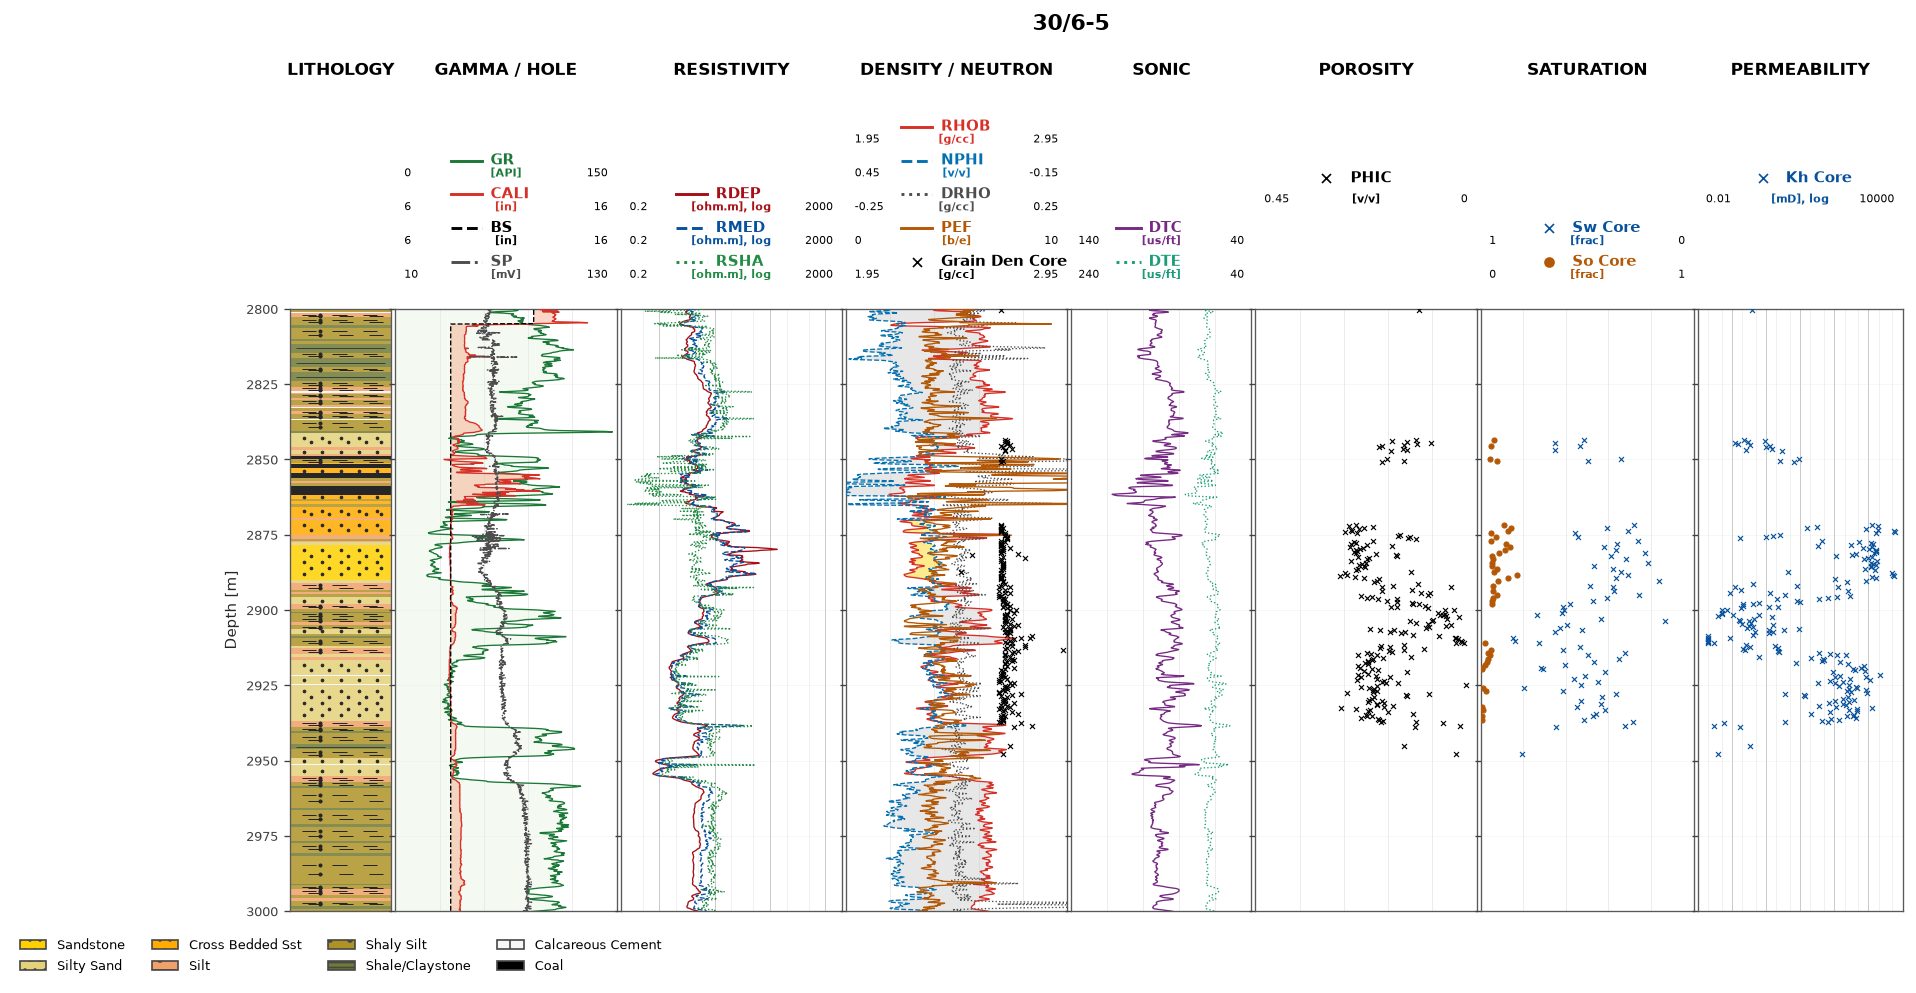

Plot diagnostics: ["SWC: inferred percent core saturation despite unit 'frac'; divided by 100 to v/v. Verify source units.", "SOC: inferred percent core saturation despite unit 'frac'; divided by 100 to v/v. Verify source units."]


In [3]:
first_well = pp.read(pp.sample("30_6-5"))
first_plot = pp.plot(first_well, top=2800, bottom=3000, figsize=(14, 8))
first_plot.show()
first_plot.close()
print("Plot diagnostics:", first_plot.warnings)

The plot cell prints two diagnostics, and both come from the bundled file itself: 30/6-5 stores core water saturation (`SWC`) and core oil saturation (`SOC`) in percent although its LAS header labels them `frac`. Petrophys detects this, converts display copies to fractions and asks you to verify the source units; both messages are kept in `first_plot.warnings`. The file on disk and the loaded `Well` are unchanged. The viewer does not draw `SOC`; `pp.interpret` (lesson 06) reports the same two curves when it reads the core data. Lesson 02 shows the evidence behind the conversion and how to declare units explicitly.

## 1. What is petrophys?

*petrophys* is a Python library for **well-log analysis and formation evaluation**. It
covers the path from a raw LAS/DLIS file to interpreted reservoir properties, and
groups its functionality into focused sub-packages. A high-level tour:

| Module | Purpose |
|---|---|
| `petrophys` (imported as `pp`) | Front door: `pp.read`, `pp.plot`, `pp.interpret`, `pp.sample`, `pp.list_samples` |
| `petrophys.io` | Format-specific readers and writers (`read_las`, `read_dlis`, `read_csv`, exporters) |
| `petrophys.model` | Core data model: the `Well` and `Curve` objects, formation tops |
| `petrophys.preprocessing` | Quality control: standardization, bad-hole, value-range, normalization |
| `petrophys.interpretation.clay_volume` | Shale/clay volume from GR, SP, neutron-density |
| `petrophys.interpretation` | Porosity, saturation, permeability, cementation |
| `petrophys.interpretation.lithology` | Multi-mineral solving |
| `petrophys.evaluation` | Net pay, BVW, rock-quality index, flow units |
| `petrophys.evaluation.summaries` | Hydrocarbon pore volume, OOIP/OGIP, zone summaries |
| `petrophys.workflow` | The dynamic workflow behind `pp.interpret`, with a step-by-step trace |
| `petrophys.visualization` | Log viewers, triple-combo, crossplots, Pickett plots |
| `petrophys.reporting` | Structured context export for reports and LLMs (lesson 19) |
| `petrophys.mcp` | MCP server that lets LLM agents drive Petrophys (lesson 20) |

We will meet many of these across the curriculum. For now, the important idea is that
**every one of them consumes the same `Well` object** - so learning to load and inspect
a well (Part A) unlocks everything else.

In [4]:
# Discover the bundled sample catalogue, by kind of data.
from petrophys.datasets import SAMPLE_KINDS

print('Bundled samples:', len(pp.list_samples()))
for kind in SAMPLE_KINDS:
    names = pp.list_samples(kind)
    print(f'{kind:<9} ({len(names):2d}): {", ".join(names)}')
print()
for collection in ('geolink', 'costa'):
    print(f'{collection:<9} ({len(pp.list_samples(collection)):2d}): {", ".join(pp.list_samples(collection))}')

Bundled samples: 61
logs      (26): 1046123714, 15_9-14, 16_7-1, 25_5-1, 30_6-5, HW-10, HW-24, HW-25, HW-26, HW-27, HW-28, HW-29, HW-3, HW-30, HW-31, HW-32, HW-4, HW-5, HW-6, HW-7, HW-8, HW-9, cheal-1, teapot_17-wx-21, teapot_44-mdx-10, tuhua-7


nmr       ( 5): daydream1_cmr, daydream1_cmr_shallow, phillips_cmr_log, phillips_gulfcoast_nmr, phillips_nmr_bins
pressure  ( 8): 319-C0009A_MDT_059LTP, 319-C0009A_MDT_067LTP, 319-C0009A_MDT_078LTP, 35_11_10_mdt, 35_11_13_mdt, c0009a_mdt_059, c0009a_mdt_067, c0009a_mdt_078


core      (12): costa_core_pc, costa_thomeer_fits, epslog_15_12_20_s_c01_grain_laser, epslog_15_12_20_s_c01_grain_segmentation, epslog_15_12_20_s_c01_strength_sonic, epslog_15_12_20_s_c01_xrf, epslog_15_12_20_s_c02_grain_laser, epslog_15_12_20_s_c02_grain_segmentation, epslog_15_12_20_s_c02_strength_sonic, epslog_15_12_20_s_c02_xrf, epslog_15_12_20_s_core, phillips_cmr_core
geology   ( 6): 1046123714_formation_tops, formations_30_6-5, formations_cheal-1, formations_costa, formations_tuhua-7, lithology_30_6-5


templates ( 4): formation_intervals_template, formation_tops_template, lithology_codes_template, lithology_intervals_template

geolink   ( 4): 15_9-14, 16_7-1, 25_5-1, 30_6-5
costa     (17): HW-10, HW-24, HW-25, HW-26, HW-27, HW-28, HW-29, HW-3, HW-30, HW-31, HW-32, HW-4, HW-5, HW-6, HW-7, HW-8, HW-9


## 2. Accessing bundled data

Two functions are all you need to reach the sample data:

- `pp.list_samples(kind=None)` - returns the names of the bundled samples, all of them
  or one kind: `'logs'` (well logs: the GeoLink North Sea wells, the COSTA carbonate
  wells, a Kansas Geological Survey legacy well, the Cheal-1 and Tuhua-7 wells of
  Taranaki, New Zealand, and two Teapot Dome wells, Wyoming), `'nmr'` (Daydream 1 CMR
  logs and NMR tables), `'pressure'` (formation-pressure tests), `'core'` (core
  measurements and capillary-pressure data), `'geology'` (formation tops and lithology
  intervals) and `'templates'` (blank input templates for your own data). A collection
  name such as `'geolink'` or `'costa'` also works.
- `pp.sample(name)` - returns the full path of that bundled file on your machine. Feed
  a well-log path straight into `pp.read(...)`.

Because the data lives inside the installed package, this works on any machine with no
setup - no downloads, no credentials, no path juggling.

In [5]:
# sample() returns a full path. Print only the file name: the folder differs by machine.
path_30_6_5 = Path(pp.sample('30_6-5'))
path_hw3 = Path(pp.sample('HW-3'))

print('30_6-5 file:', path_30_6_5.name, '| exists:', path_30_6_5.is_file())
print('HW-3   file:', path_hw3.name, '| exists:', path_hw3.is_file())

30_6-5 file: 30_6-5.las | exists: True
HW-3   file: HW-3.las | exists: True


## 3. Tour - dataset one: GeoLink (North Sea clastics)

The **GeoLink** wells are siliciclastic (sand/shale) wells from the Norwegian North
Sea. Our **primary teaching well is 30/6-5** from Oseberg Øst: it is unusually
rich, carrying not just the standard triple-combo logs but also core
porosity/permeability measurements and a supplied lithology track - ideal for teaching.
Its reservoir is the Brent Group, 2841-2958 m (Ness and Etive formations), so many
later lessons zoom into that depth window.

Let us load it and read off the basic facts.

In [6]:
w_geo = pp.read(pp.sample('30_6-5'))

# header.field can contain non-ASCII field names; print an ASCII-safe version.
field_ascii = (w_geo.header.field or '').encode('ascii', 'replace').decode('ascii')

print('=== GeoLink well 30/6-5 ===')
print('Well name    :', w_geo.name)
print('Field        :', field_ascii)
print('UWI          :', w_geo.header.uwi)
print('# curves     :', w_geo.n_curves)
print('# samples    :', w_geo.n_samples)
print('Depth unit   :', w_geo.depth_unit)
print('Depth range  : %.2f -> %.2f %s' % (w_geo.start_depth, w_geo.stop_depth, w_geo.depth_unit))
print('Sample step  : %.4f %s' % (w_geo.step, w_geo.depth_unit))
print()
print('Curves:')
print('  ' + ', '.join(w_geo.curves))

=== GeoLink well 30/6-5 ===
Well name    : 30/6-5
Field        : OSEBERG ?ST
UWI          : 30/6-5
# curves     : 20
# samples    : 22176
Depth unit   : m
Depth range  : 176.61 -> 3556.08 m
Sample step  : 0.1524 m

Curves:
  LITHOLOGY_GEOLINK, CALI, DRHO, NPHI, RHOB, PEF, GR, DTC, DTE, RDEP, SP, RSHA, RMED, BS, PHIC, GDEN, KH_CORE, KV_CORE, SWC, SOC


Notice a few things about `30_6-5`:

- Depth is in **metres** (`m`) - a European convention.
- Alongside the classic logs (`GR`, `RHOB`, `NPHI`, `PEF`, `DTC`, resistivities `RDEP`,
  `RMED`, `RSHA`, `SP`) it carries **`CALI`** (caliper) and **`BS`** (bit size), which
  we will use for bad-hole detection in lesson 02.
- It has **core data**: `KH_CORE`/`KV_CORE` (horizontal/vertical permeability),
  `PHIC` (core porosity), plus `SWC`/`SOC`. Core-calibrated wells are gold for
  benchmarking log-derived answers.
- It even ships a supplied `LITHOLOGY_GEOLINK` track.

## 4. Tour - dataset two: COSTA (carbonate)

The **COSTA** dataset is a public carbonate reservoir benchmark; Petrophys bundles 17 of
its wells (`HW-3` through `HW-32`). Carbonate petrophysics differs from clastics
(complex pore systems, different lithology solving, Archie parameters `a`, `m`, `n`
that vary with texture), so having carbonate wells lets the curriculum contrast the
two rock types.

Each COSTA LAS file covers **only the Kharaib-2 reservoir interval**, not the whole
well: the logged depth range *is* the Kharaib-2 reservoir zone. The bundled `formations_costa` table
records that interval for every well. The files are leaner and more uniform than
30/6-5 - a realistic multi-well set for teaching **normalization** across a field. Let
us load `HW-3` and look up its interval.

In [7]:
w_car = pp.read(pp.sample('HW-3'))

print('=== COSTA well HW-3 ===')
print('Well name    :', w_car.name)
print('Field        :', w_car.header.field)
print('UWI          :', w_car.header.uwi)
print('# curves     :', w_car.n_curves)
print('# samples    :', w_car.n_samples)
print('Depth unit   :', w_car.depth_unit)
print('Depth range  : %.2f -> %.2f %s' % (w_car.start_depth, w_car.stop_depth, w_car.depth_unit))
print('Sample step  : %.4f %s' % (w_car.step, w_car.depth_unit))
print()
print('Curves:')
print('  ' + ', '.join(w_car.curves))

interval = pp.read_formations(pp.sample('formations_costa'), well=w_car)
print()
print('Logged interval:')
print(interval[['formation_name', 'top_depth', 'bottom_depth', 'depth_unit']].to_string(index=False))

=== COSTA well HW-3 ===
Well name    : HW-3
Field        : COSTA
UWI          : HW-3
# curves     : 8
# samples    : 431
Depth unit   : ft
Depth range  : 7805.00 -> 8020.00 ft
Sample step  : 0.5000 ft

Curves:
  GR, RHOB, NPHI, DT, PHIE_CC, RT, SW_INPUT, PERM_CC

Logged interval:
formation_name  top_depth  bottom_depth depth_unit
     KHARAIB-2     7805.0        8020.0         ft


Contrast with the GeoLink well:

- Depth here is in **feet** (`ft`), as is usual in North America and the Middle East. Mixed depth units across
  datasets is exactly why unit awareness (lesson 02) matters.
- The file spans a few hundred feet because it holds only the Kharaib-2 interval; the
  30/6-5 file spans the whole logged well.
- The COSTA curve set is compact: `GR`, `RHOB`, `NPHI`, `DT` (sonic), `RT` (true
  resistivity), plus the interpretation-input curves `PHIE_CC` (core-corrected effective
  porosity), `PERM_CC` (core-corrected permeability) and `SW_INPUT` (the source
  water saturation). These are continuous log curves supplied with the dataset,
  not core-plug measurements.
- No caliper/bit-size here - so bad-hole detection (lesson 02) will be demonstrated on
  the GeoLink well, and normalization on the COSTA wells.

Let us put the two side by side.

In [8]:
summary = pd.DataFrame([
    {'well': w_geo.name, 'dataset': 'GeoLink (clastic)', 'rock': 'sand/shale',
     'logged interval': 'whole well',
     'depth_unit': w_geo.depth_unit, 'n_curves': w_geo.n_curves,
     'n_samples': w_geo.n_samples,
     'top': round(w_geo.start_depth, 1), 'base': round(w_geo.stop_depth, 1)},
    {'well': w_car.name, 'dataset': 'COSTA (carbonate)', 'rock': 'carbonate',
     'logged interval': 'Kharaib-2 only',
     'depth_unit': w_car.depth_unit, 'n_curves': w_car.n_curves,
     'n_samples': w_car.n_samples,
     'top': round(w_car.start_depth, 1), 'base': round(w_car.stop_depth, 1)},
])
summary

,well,dataset,rock,logged interval,depth_unit,n_curves,n_samples,top,base
0,30/6-5,GeoLink (clastic),sand/shale,whole well,m,20,22176,176.6,3556.1
1,HW-3,COSTA (carbonate),carbonate,Kharaib-2 only,ft,8,431,7805.0,8020.0


## 5. A first look at the logs

To make the two wells concrete, here is the gamma-ray log from each, plotted against
depth (log convention: depth increasing downward). GR distinguishes clean reservoir
(low GR) from shale/clay (high GR). Notice how different the two GR *scales* are - the
COSTA carbonate interval reads far lower than the North Sea shales. That contrast is real
lithology, not a tool artifact. Multi-well **normalization** (lesson 02) solves a
different problem: correcting well-to-well calibration bias between wells of the
*same* field.

[repository]\src\petrophys\preprocessing\standardization\curve_standardizer.py:834: UserWarning: SWC: inferred percent core saturation despite unit 'frac'; divided by 100 to v/v. Verify source units.
  standardize_core_saturation(new_curve, inplace=True)
[repository]\src\petrophys\preprocessing\standardization\curve_standardizer.py:834: UserWarning: SOC: inferred percent core saturation despite unit 'frac'; divided by 100 to v/v. Verify source units.
  standardize_core_saturation(new_curve, inplace=True)


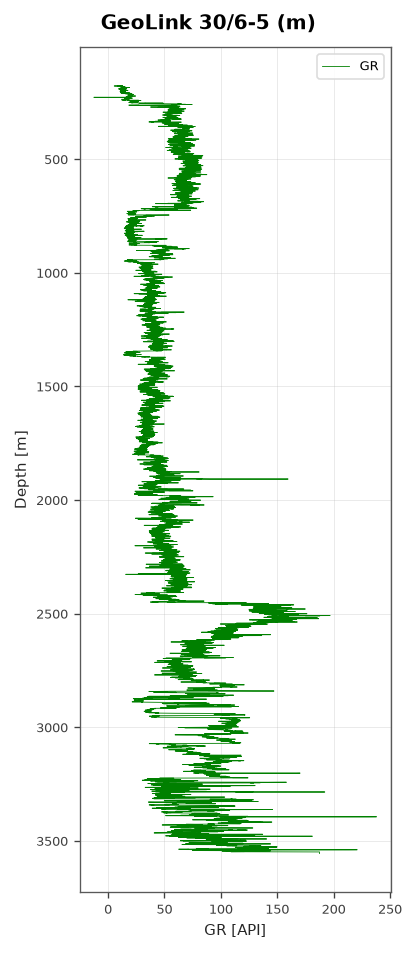

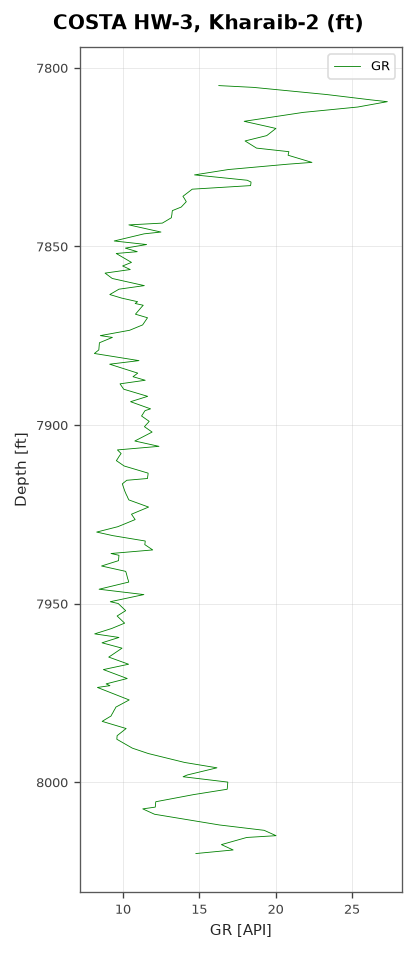

GR ranges -> GeoLink: -13..238  |  COSTA: 8..27


In [9]:
# GR first-look via the library LogPlot (one single-track plot per well,
# since the two wells are on different depth units - m vs ft).
from petrophys.visualization import LogPlot

for w, title in [(w_geo, 'GeoLink 30/6-5 (m)'), (w_car, 'COSTA HW-3, Kharaib-2 (ft)')]:
    lp = LogPlot(w, figsize=(3.5, 8))
    lp.create_figure(n_tracks=1)
    lp.add_curve(0, 'GR', color='green')
    lp.add_title(title)
    lp.show()

print('GR ranges -> GeoLink: %.0f..%.0f  |  COSTA: %.0f..%.0f'
      % (w_geo.get('GR').min(), w_geo.get('GR').max(),
         w_car.get('GR').min(), w_car.get('GR').max()))

## 6. Curriculum roadmap

Two short pages of the documentation sit in front of the lessons:

- **[Quickstart](../../docs/quickstart.md)** - read, plot and interpret one bundled well
  with the front-door API, then inspect the decisions.
- **[Your own data](../../docs/own_data.md)** - LAS, CSV/TSV and Excel inputs, optional
  formation and lithology tables, depth metadata and diagnostics.

The lessons are split into two parts.

### Part A - Foundations & Core Science (you are here)
| # | Lesson | What you learn |
|---|---|---|
| 00 | Orientation and setup | This lesson: purpose, data, roadmap |
| 01 | Loading and inspecting data | The `Well` / `Curve` data model in depth |
| 02 | QA/QC and standardization | Conditioning: aliases, units, bad-hole, normalization |
| 03 | Clay volume | Vcl from GR (linear/Larionov/Stieber/Clavier), SP, neutron-density |
| 04 | Porosity | Density/neutron/sonic; total vs effective; hydrocarbon correction |
| 05 | Lithology and mineral solver | N-D/PEF crossplots; 2- and 3-mineral least-squares solving |
| 06 | Formation water and environment | Rw (SP/salinity), Rmf, temperature profile, invasion |
| 07 | Water saturation | Archie + shaly-sand models; Pickett m/n; model selection |
| 08 | Permeability | Timur/Coates; core poro-perm calibration |
| 09 | Reservoir quality and net pay | RQI/FZI/flow units; BVW/MHI; net pay; HCPV/OOIP/OGIP |

### Part B - Integrated & Advanced Workflows
Building on the foundations from Part A, Part B covers the integrated and specialist
workflows:

| # | Lesson | What you learn |
|---|---|---|
| 10 | Dynamic workflow (glass box) | Auto method selection, the ordered workflow steps (listed below), step traces, overrides |
| 11 | Formation and interval analysis | Tops, zones/subzones, per-interval and formation summaries |
| 12 | Core calibration and digital core | Core-to-log calibration; digital-core facies, XRF, geomechanics |
| 13 | ML curve imputation | Rebuild missing curve samples from the other logs with `pp.impute` |
| 14 | NMR petrophysics | T2 bins; SDR and Coates permeability; BVI/FFI |
| 15 | Capillary pressure and saturation-height | J-function, Brooks-Corey fitting, Pc-height conversion |
| 16 | Borehole image (FMI) | Pads to oriented image, equalization, azimuthal coverage |
| 17 | Visualization masterclass | XML templates, adaptive viewer, crossplots, batch export |
| 18 | Multiwell field study | COSTA 17-well batch, normalization, portfolio summary |
| 19 | LLM context generation | Export structured, size-limited context from interpreted wells |
| 20 | Petrophys for LLM agents (MCP) | Drive loading, interpretation, summaries and plots from an MCP client |
| 21 | Custom workflows | Build, validate and save your own reusable `Workflow` recipe |

Each lesson consumes exactly the `Well` object you learn to build here in Part A.

The dynamic workflow behind `pp.interpret` is organized as an ordered catalogue of
steps. Each run records which steps executed and which were skipped, with a reason,
so the catalogue is not a promise that every step runs on every well:

In [10]:
from petrophys.workflow import workflow_steps

steps = workflow_steps()
print(f'{len(steps)} workflow steps, in execution order:')
for number, step in enumerate(steps, 1):
    print(f"{number:2d}. {step['name']:<23} {step['description']}")

21 workflow steps, in execution order:
 1. normalization           Canonical curve aliases and units; implausible-value screening
 2. temperature             Formation temperature profile from BHT or a gradient
 3. bad_hole                Washout and density-correction quality flags
 4. spectral_gamma          Not run by pp.interpret; call petrophys.interpretation.geochemistry.interpret_spectral_gamma directly
 5. elemental_spectroscopy  Not run by pp.interpret; call petrophys.interpretation.geochemistry.interpret_elemental_spectroscopy directly
 6. vclay                   Clay volume (VCL) from gamma ray, SP and neutron-density
 7. rcl                     Clay resistivity from shale intervals
 8. rmf                     Mud-filtrate resistivity at formation temperature
 9. hc_correction           Neutron-density hydrocarbon correction (opt-in)
10. porosity                Density, neutron, sonic, total (PHIT) and effective (PHIE) porosity
11. lithology               Mineral volumes: cl

## 7. What this curriculum does not cover

To set honest expectations, the curriculum focuses on **wireline log analysis and
formation evaluation**. The following are outside its scope:

- **Seismic and AVO** - no seismic inversion, amplitude-versus-offset, or
  rock-physics-to-seismic tie.
- **Geomechanics** - beyond limited digital-core mechanical properties, no full wellbore
  stability / stress modelling.
- **Unconventionals / TOC** - no organic-richness (total organic carbon) or
  source-rock workflows.
- **4D (time-lapse)** - no repeat-survey / production monitoring.
- **Monte-Carlo uncertainty** - results in these lessons are deterministic. The
  library has a Monte-Carlo propagator (`petrophys.evaluation.monte_carlo`, shown in
  the analysis-tools page of the documentation), but no lesson teaches it.

Knowing the boundary is part of using any tool responsibly.

## Pitfalls and good habits

- **Mind the depth unit.** GeoLink is in metres, COSTA in feet. Always read
  `w.depth_unit` before comparing depths or thicknesses across wells.
- **Know what interval a file covers.** 30/6-5 spans the whole logged well; each COSTA
  file spans only the Kharaib-2 reservoir interval.
- **Use `sample()` for paths, never hard-code them.** The bundled data path differs by
  machine; `pp.sample(name)` resolves it for you.
- **Non-ASCII header fields happen.** Legacy LAS headers (like the Oseberg field name)
  can carry odd encodings; sanitize before printing if you need clean ASCII output.
- **Read warnings.** A diagnostic such as the SWC percent-versus-fraction message is a
  finding about the data, not noise to hide.
- **Core curves are precious.** When a well carries core measurements (`*_CORE`, `PHIC`),
  use them to validate your log-derived answers. `*_CC` curves are core-corrected log
  curves: useful, but not independent core data.

## Recap

- *petrophys* is a well-log / formation-evaluation library; every sub-package consumes
  the same `Well` object, and `pp.read`, `pp.plot` and `pp.interpret` are the front door.
- `pp.list_samples(...)` lists the bundled samples (LAS and DLIS logs, CSV and Excel tables);
  `pp.sample(name)` gives the file path to feed `pp.read(...)` (which uses the
  lower-level `petrophys.io.read_las` for LAS files).
- Two main teaching datasets: **GeoLink** North Sea clastics (primary well 30/6-5,
  metres, core-rich, Brent Group 2841-2958 m) and **COSTA** carbonates
  (`HW-3 ... HW-32`, feet, each file only the Kharaib-2 interval).
- The curriculum starts with the quickstart and own-data pages, then runs Part A
  (lessons 00-09: loading and QA/QC through saturation, permeability and net pay) and
  Part B (lessons 10-21: integrated workflows, specialist data, multiwell studies,
  LLM integration and custom workflows).
- Seismic/AVO, full geomechanics, unconventionals/TOC and 4D are outside the
  curriculum, and no lesson teaches Monte-Carlo uncertainty.
- Start with read/plot; add `pp.interpret` only when ready to review its assumptions and
  trace. It works on a copy of the well.

## Try it yourself

> **Exercise 1.** Load a *second* COSTA well (e.g. `HW-10`) and a *second* GeoLink well
> (e.g. `25_5-1`). Print each well's name, curve count, depth unit and depth range. Do
> all COSTA wells share the same curve set? Does the Kharaib-2 interval sit at the same
> depth in every COSTA well?
>
> **Exercise 2.** For any well, list which curves contain the substring `CORE` or `CC`
> (core measurements, or log curves corrected to core). Which of the two datasets
> carries actual core-plug measurements?

*Hint:* iterate over `pp.list_samples('costa')`, and use `pp.read(pp.sample(name))`.

## What's next

Continue with **`01_loading_and_inspecting_data.ipynb`**, where we open up the `Well` and
`Curve` objects properly: headers, per-curve statistics, DataFrame export, depth slicing,
and the difference between the curve sets of a clastic and a carbonate well.